In [ ]:
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import timm
import numpy as np
from image_preprocess import prepare_datasets 

# Configuration
DATASET_PATH = 'dataset/aerial_landscapes'
NUM_CLASSES = 15
BATCH_SIZE = 1
SEED = 18
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_FILE = "best_model_efficientnet_b0.pth"
TRAIN_ACCS_FILE = "train_accs_efficientnet_b0.npy"
VAL_ACCS_FILE = "val_accs_efficientnet_b0.npy"

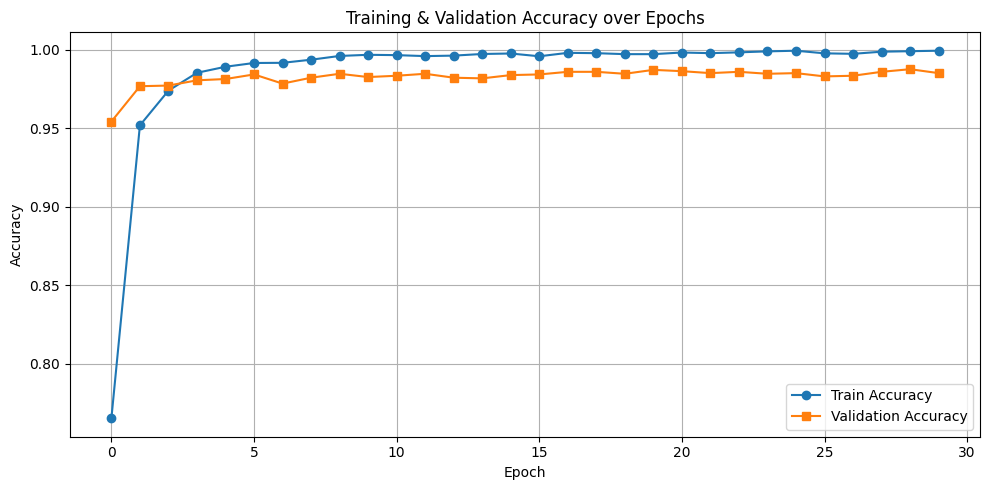

In [2]:
train_accs = np.load(TRAIN_ACCS_FILE)
val_accs = np.load(VAL_ACCS_FILE)

plt.figure(figsize=(10, 5))
plt.plot(train_accs, label="Train Accuracy", marker='o')
plt.plot(val_accs, label="Validation Accuracy", marker='s')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training & Validation Accuracy over Epochs")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [3]:
# Set random seed
torch.manual_seed(SEED)

_, test_dataset = prepare_datasets(DATASET_PATH, seed=SEED)
class_names = test_dataset.subset.dataset.classes

def evaluate_model(model_file, test_dataset):
    # Load test set
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
    # Load model
    model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=NUM_CLASSES)
    model.load_state_dict(torch.load(model_file, map_location=DEVICE))
    model.eval().to(DEVICE)

    # Collect predictions
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return all_preds, all_labels


def plot_confusion_matrix(class_names, all_labels, all_preds, title):
    # Compute confusion matrix
    cm = confusion_matrix(all_labels, all_preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    # Plot
    fig, ax = plt.subplots(figsize=(12, 10))
    disp.plot(ax=ax, cmap='Blues', xticks_rotation=45)
    plt.title(title)
    plt.tight_layout()
    plt.show()

In [4]:
all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset)

# Classification Report
print("\nClassification Report:")
original_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      1.000     0.988     0.994       160
     Airport      0.987     0.981     0.984       160
       Beach      0.994     0.994     0.994       160
        City      0.975     0.994     0.985       160
      Desert      0.987     0.975     0.981       160
      Forest      0.994     0.981     0.987       160
   Grassland      0.981     0.981     0.981       160
     Highway      0.975     0.988     0.981       160
        Lake      1.000     0.994     0.997       160
    Mountain      0.963     0.988     0.975       160
     Parking      1.000     0.994     0.997       160
        Port      0.994     1.000     0.997       160
     Railway      0.987     0.963     0.975       160
 Residential      0.988     1.000     0.994       160
       River      0.988     0.994     0.991       160

    accuracy                          0.988      2400
   macro avg      0.988     0.988     0.988      2400
we

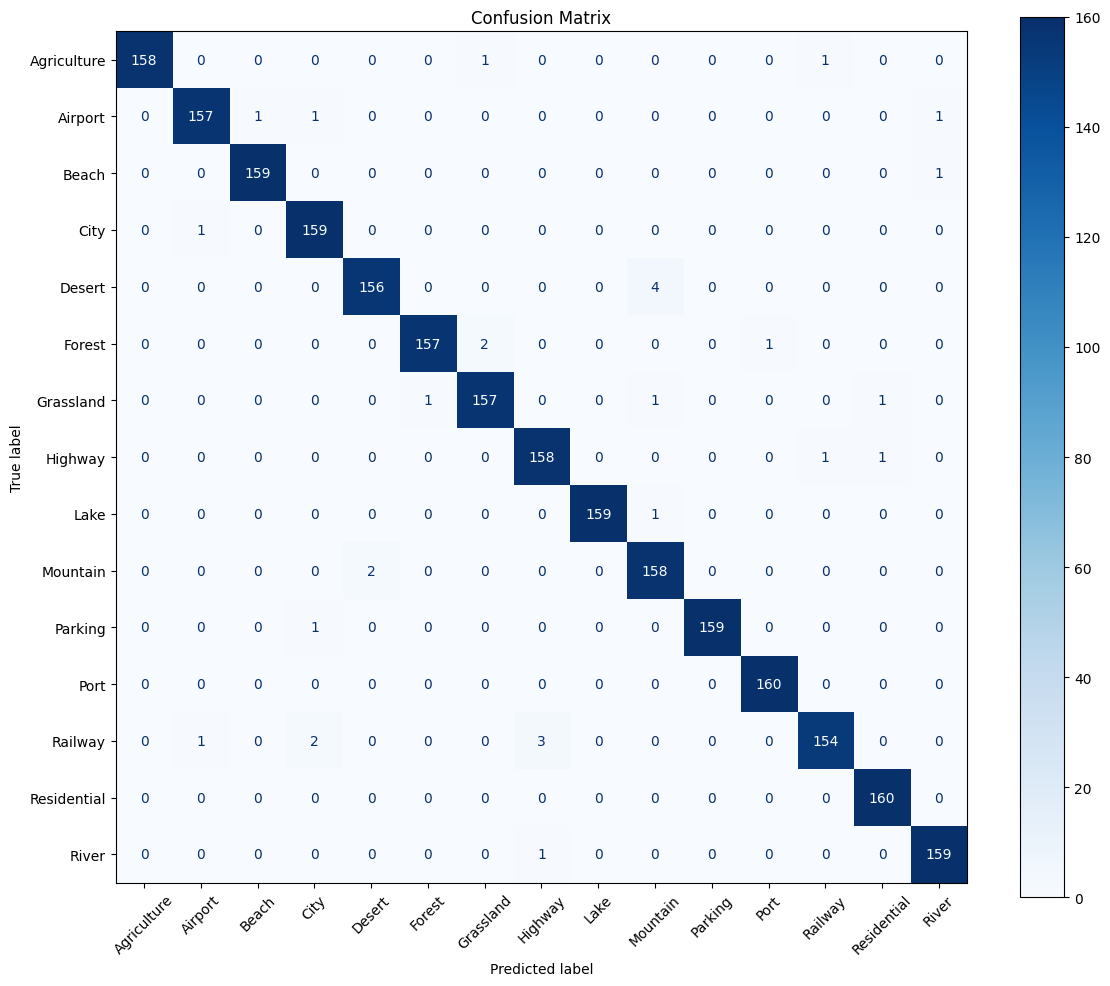

In [5]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

In [6]:
from image_preprocess import MyDataset
from utils.dataset_utils import get_blur_transform, get_noise_transform, get_patch_transform

raw_test_subset = test_dataset.subset  
test_dataset_patch = MyDataset(raw_test_subset, get_patch_transform())
test_dataset_blur  = MyDataset(raw_test_subset, get_blur_transform())
test_dataset_noise = MyDataset(raw_test_subset, get_noise_transform())

In [7]:
all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset_patch)

# Classification Report
print("\nClassification Report:")
patch_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      1.000     0.988     0.994       160
     Airport      0.994     0.975     0.984       160
       Beach      0.994     0.994     0.994       160
        City      0.941     0.994     0.967       160
      Desert      0.981     0.944     0.962       160
      Forest      0.994     0.956     0.975       160
   Grassland      0.969     0.981     0.975       160
     Highway      0.975     0.988     0.981       160
        Lake      0.878     0.994     0.933       160
    Mountain      0.987     0.938     0.962       160
     Parking      1.000     0.988     0.994       160
        Port      0.988     1.000     0.994       160
     Railway      0.987     0.944     0.965       160
 Residential      0.988     0.994     0.991       160
       River      1.000     0.981     0.991       160

    accuracy                          0.977      2400
   macro avg      0.978     0.977     0.977      2400
we

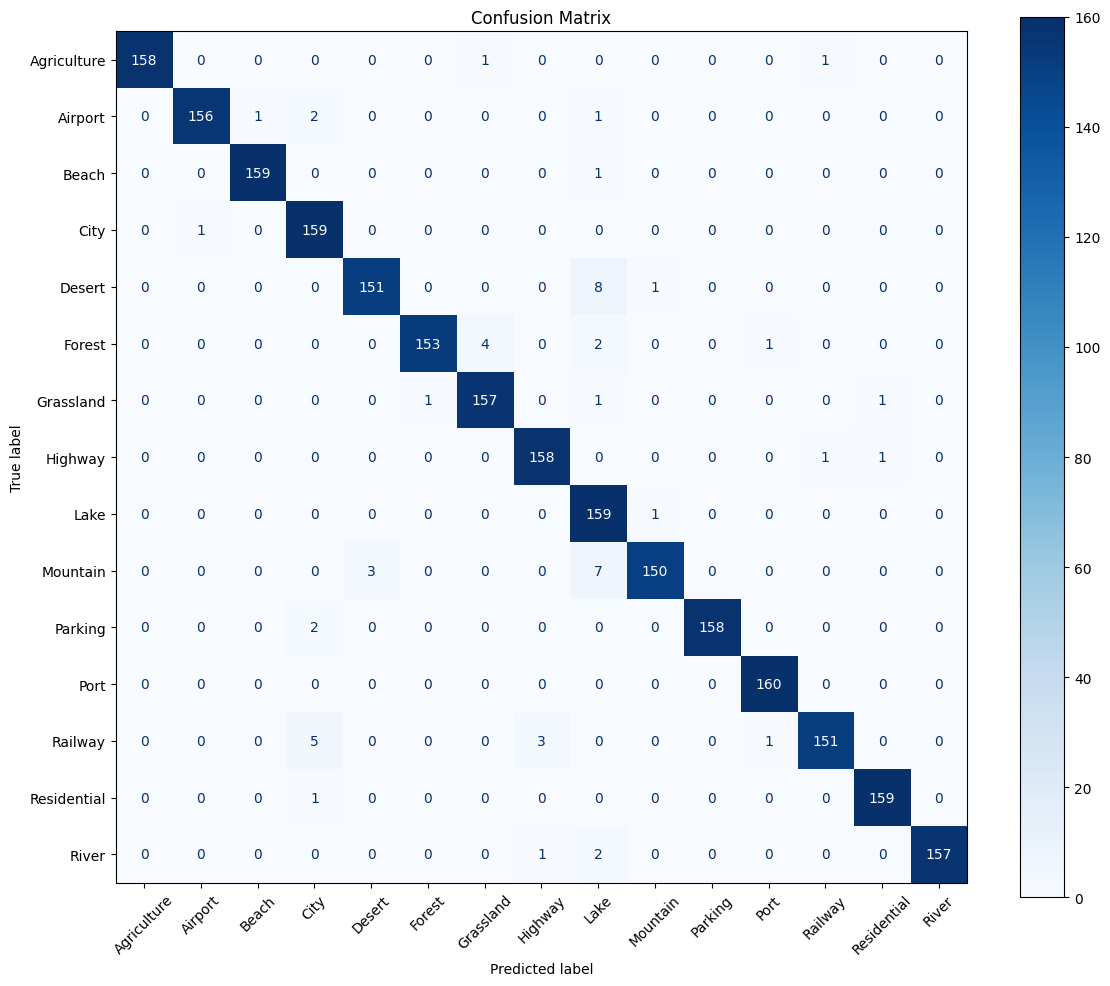

In [8]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

In [9]:
all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset_blur)

# Classification Report
print("\nClassification Report:")
blur_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      0.991     0.669     0.799       160
     Airport      0.926     0.469     0.622       160
       Beach      0.734     0.950     0.828       160
        City      0.911     0.894     0.902       160
      Desert      0.506     0.994     0.671       160
      Forest      0.832     0.869     0.850       160
   Grassland      0.922     0.744     0.824       160
     Highway      0.880     0.912     0.896       160
        Lake      0.901     0.969     0.934       160
    Mountain      0.926     0.544     0.685       160
     Parking      0.962     0.938     0.949       160
        Port      0.945     0.856     0.898       160
     Railway      0.760     0.869     0.810       160
 Residential      0.984     0.794     0.879       160
       River      0.781     0.938     0.852       160

    accuracy                          0.827      2400
   macro avg      0.864     0.827     0.827      2400
we

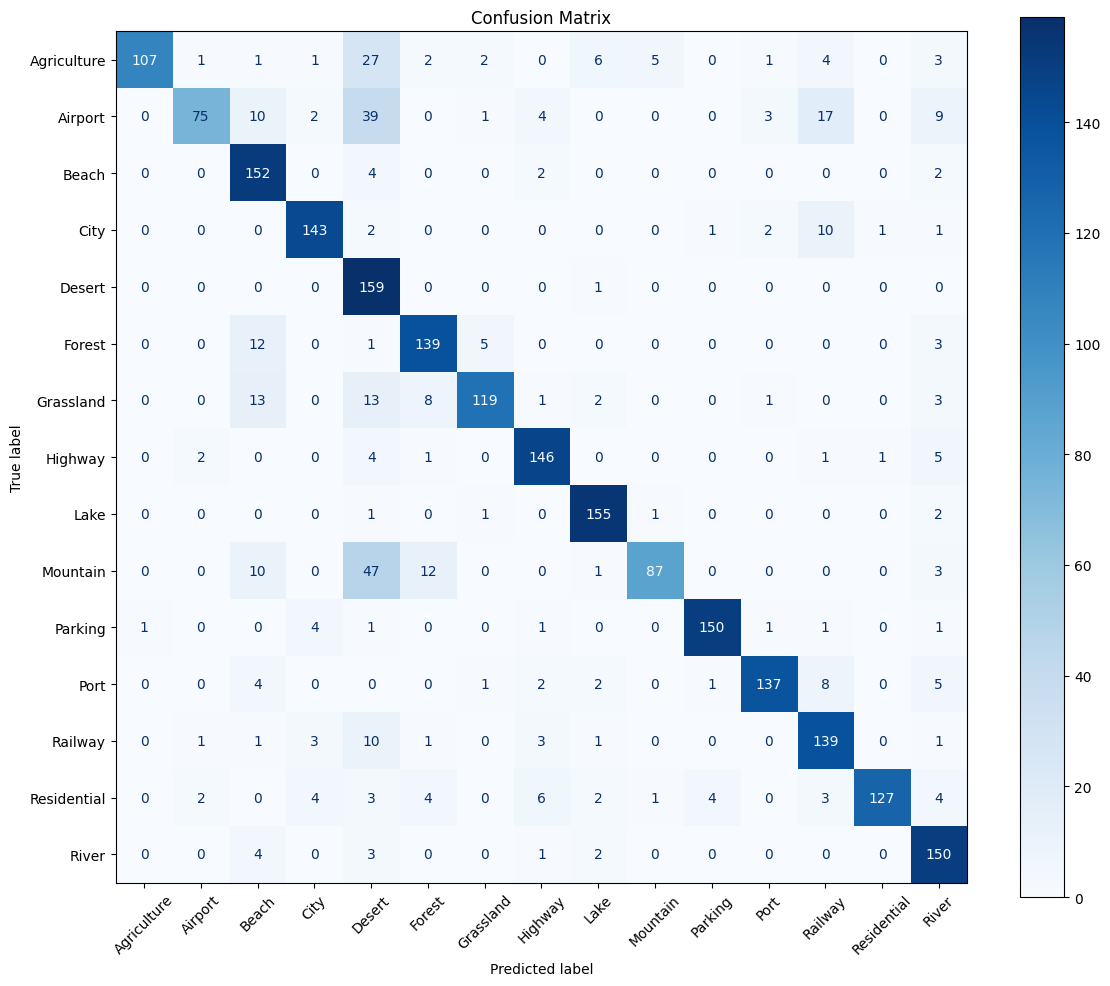

In [10]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

In [15]:
all_preds,all_labels = evaluate_model(MODEL_FILE, test_dataset_noise)

# Classification Report
print("\nClassification Report:")
noise_classification_report=classification_report(all_labels, all_preds, target_names=class_names, digits=3, output_dict=True)
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))


Classification Report:
              precision    recall  f1-score   support

 Agriculture      1.000     0.019     0.037       160
     Airport      0.000     0.000     0.000       160
       Beach      0.917     0.069     0.128       160
        City      0.875     0.044     0.083       160
      Desert      0.074     1.000     0.138       160
      Forest      0.304     0.087     0.136       160
   Grassland      0.000     0.000     0.000       160
     Highway      0.917     0.138     0.239       160
        Lake      0.786     0.069     0.126       160
    Mountain      0.500     0.013     0.024       160
     Parking      1.000     0.056     0.107       160
        Port      0.732     0.375     0.496       160
     Railway      0.857     0.075     0.138       160
 Residential      0.000     0.000     0.000       160
       River      0.842     0.100     0.179       160

    accuracy                          0.136      2400
   macro avg      0.587     0.136     0.122      2400
we

c:\Users\arrow\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\arrow\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\arrow\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

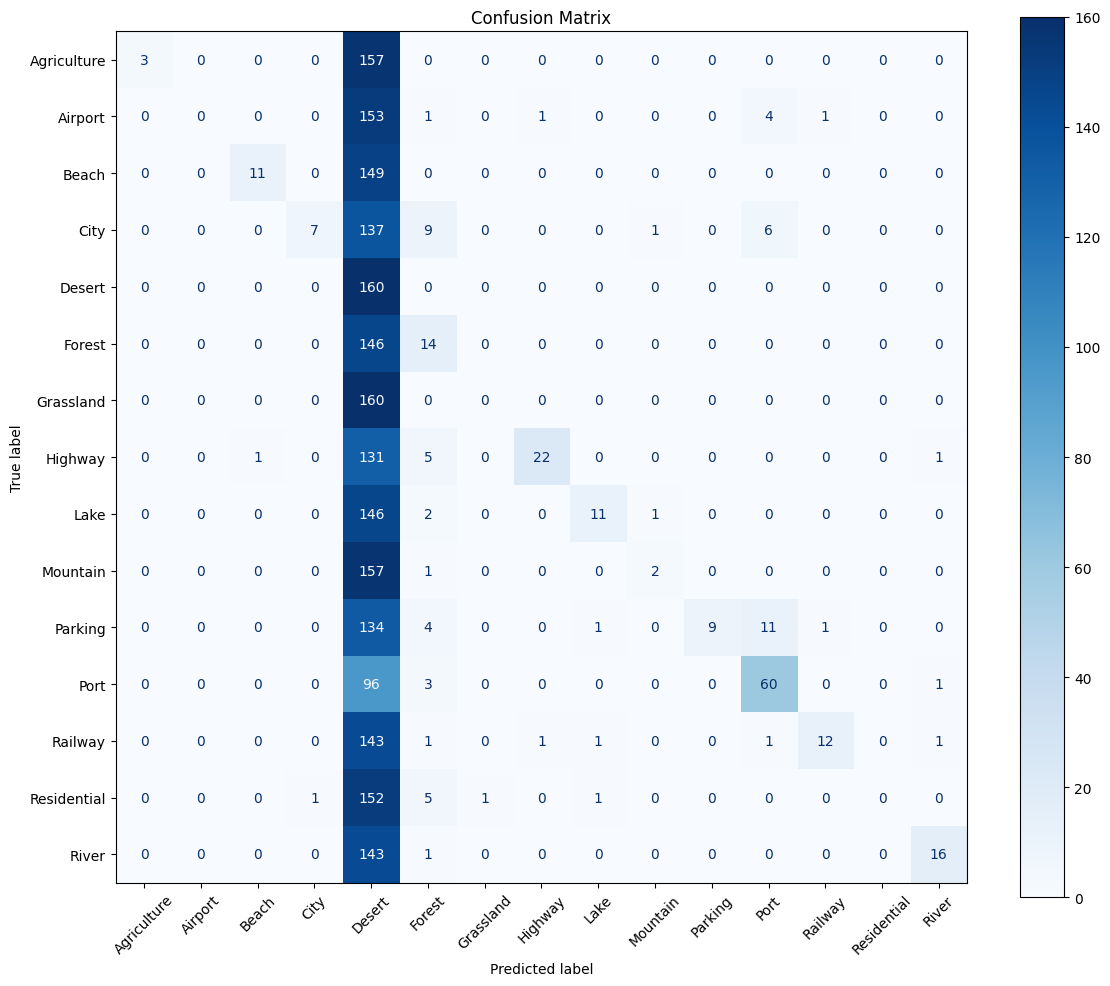

In [16]:
plot_confusion_matrix(class_names, all_labels, all_preds, "Confusion Matrix")

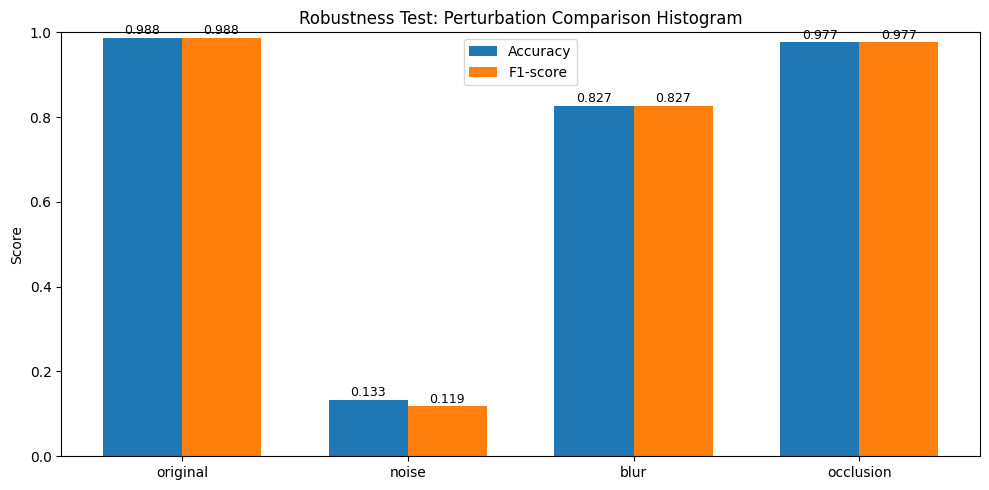

In [13]:
reports = {
    "original": original_classification_report,
    "noise": noise_classification_report,
    "blur": blur_classification_report,
    "occlusion": patch_classification_report
}

# Prepare data
perturbations = ["original", "noise", "blur", "occlusion"]
accuracies = [reports[p]['accuracy'] for p in perturbations]
f1_scores = [reports[p]['macro avg']['f1-score'] for p in perturbations]

# Set bar positions
x = range(len(perturbations))
width = 0.35

# Plot
plt.figure(figsize=(10, 5))
plt.bar([i - width/2 for i in x], accuracies, width=width, label='Accuracy')
plt.bar([i + width/2 for i in x], f1_scores, width=width, label='F1-score')

plt.xticks(ticks=x, labels=perturbations)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Robustness Test: Perturbation Comparison Histogram")
plt.legend()
for i in range(len(perturbations)):
    plt.text(i - width/2, accuracies[i] + 0.001, f"{accuracies[i]:.3f}", ha='center', va='bottom', fontsize=9)
    plt.text(i + width/2, f1_scores[i] + 0.001, f"{f1_scores[i]:.3f}", ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()
